In [16]:
import os
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Resolution-safe defaults for this notebook.
NOTEBOOK_DIR = Path.cwd()
TRAIN_DIR = NOTEBOOK_DIR / 'train'
VALID_DIR = NOTEBOOK_DIR / 'valid'
TEST_DIR = NOTEBOOK_DIR / 'test'
BASE_MODEL_PATH = NOTEBOOK_DIR / 'CNN_A.keras'

print(f'Base model exists: {BASE_MODEL_PATH.exists()}')
print(f'Train directory exists: {TRAIN_DIR.exists()}')

# Force CPU if GPU is unavailable or if Metal/XLA is not working in this environment.
try:
    tf.config.list_physical_devices("GPU")
    print("Using GPU for model creation and tuning.")
except RuntimeError:
    print("Using CPU for model creation and tuning.")
    pass

plt.rcParams['font.size'] = 14
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['legend.fontsize'] = 12


Base model exists: True
Train directory exists: True
Using GPU for model creation and tuning.


In [21]:
# Define the data generators for the bird image dataset.
# The pretrained model was trained on 128 x 128 inputs, so we keep the same image size here.
train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode="nearest"
)
valid_gen = ImageDataGenerator(rescale=1./255)
test_gen = ImageDataGenerator(rescale=1./255)

train_flow = train_gen.flow_from_directory(
    str(TRAIN_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True,
)

valid_flow = valid_gen.flow_from_directory(
    str(VALID_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False,
)

test_flow = test_gen.flow_from_directory(
    str(TEST_DIR),
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False,
)

train_counts = Counter()
valid_counts = Counter()
test_counts = Counter()

for split_name, directory in [('train', TRAIN_DIR), ('valid', VALID_DIR), ('test', TEST_DIR)]:
    for class_dir in sorted(directory.iterdir()):
        if class_dir.is_dir():
            count = len(list(class_dir.glob('*')))
            if split_name == 'train':
                train_counts[class_dir.name] = count
            elif split_name == 'valid':
                valid_counts[class_dir.name] = count
            else:
                test_counts[class_dir.name] = count

print('Train class counts:', dict(train_counts))
print('Validation class counts:', dict(valid_counts))
print('Test class counts:', dict(test_counts))



Found 2110 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Found 50 images belonging to 10 classes.
Train class counts: {'ANTILLEAN EUPHONIA': 211, 'BANDED STILT': 211, 'BLACK AND YELLOW BROADBILL': 211, 'CRESTED COUA': 211, 'EASTERN GOLDEN WEAVER': 211, 'FLAME TANAGER': 211, 'GOLDEN BOWER BIRD': 211, 'MAGPIE GOOSE': 211, 'WILD TURKEY': 211, 'WOOD THRUSH': 211}
Validation class counts: {'ANTILLEAN EUPHONIA': 5, 'BANDED STILT': 5, 'BLACK AND YELLOW BROADBILL': 5, 'CRESTED COUA': 5, 'EASTERN GOLDEN WEAVER': 5, 'FLAME TANAGER': 5, 'GOLDEN BOWER BIRD': 5, 'MAGPIE GOOSE': 5, 'WILD TURKEY': 5, 'WOOD THRUSH': 5}
Test class counts: {'ANTILLEAN EUPHONIA': 5, 'BANDED STILT': 5, 'BLACK AND YELLOW BROADBILL': 5, 'CRESTED COUA': 5, 'EASTERN GOLDEN WEAVER': 5, 'FLAME TANAGER': 5, 'GOLDEN BOWER BIRD': 5, 'MAGPIE GOOSE': 5, 'WILD TURKEY': 5, 'WOOD THRUSH': 5}


In [ ]:
# Use class weighting instead of duplicating training images.
# This addresses the imbalance in the training split without altering the dataset.
class_indices = train_flow.class_indices
class_weights = {}
train_total = sum(train_counts.values())
num_classes = len(train_counts)
for class_name, idx in class_indices.items():
    class_count = train_counts[class_name]
    class_weights[idx] = train_total / (num_classes * class_count)

print('Class weights:', class_weights)


ANTILLEAN EUPHONIA: 211
BANDED STILT: 211
BLACK AND YELLOW BROADBILL: 211
CRESTED COUA: 211
EASTERN GOLDEN WEAVER: 211
FLAME TANAGER: 211
GOLDEN BOWER BIRD: 211
MAGPIE GOOSE: 211
WILD TURKEY: 211
WOOD THRUSH: 211


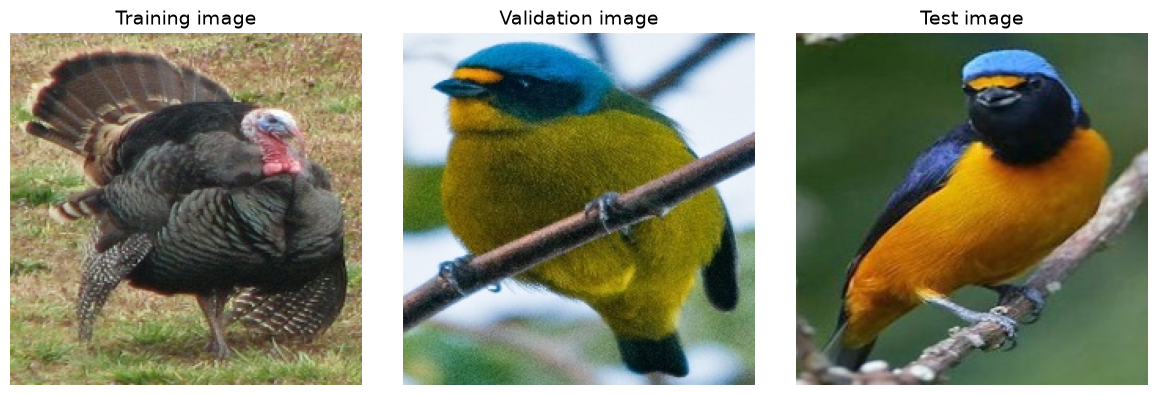

In [3]:
# Visualise a few representative examples from each split.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

sample_train = train_flow[0][0][0]
sample_valid = valid_flow[0][0][0]
sample_test = test_flow[0][0][0]

axes[0].imshow(sample_train)
axes[0].set_title('Training image')
axes[0].axis('off')

axes[1].imshow(sample_valid)
axes[1].set_title('Validation image')
axes[1].axis('off')

axes[2].imshow(sample_test)
axes[2].set_title('Test image')
axes[2].axis('off')

plt.tight_layout()
plt.show()


In [4]:
# Load the saved CNN from the previous stage and inspect its structure.
base_model = tf.keras.models.load_model(str(BASE_MODEL_PATH))
base_model.summary()

print(f'Loaded base model from: {BASE_MODEL_PATH}')
print(f'Input shape: {base_model.input_shape}')
print(f'Output shape: {base_model.output_shape}')


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 112, 112, 128)  │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 56, 56, 32)     │       102,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 28, 28, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 587,904 (2.24 MB)

 Trainable params: 195,754 (764.66 KB)

 Non-trainable params: 640 (2.50 KB)

 Optimizer params: 391,510 (1.49 MB)

Loaded base model from: /Users/lauryn/Documents/advanced_ml/tl/CNN_A.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 10)


In [5]:
# Freeze the base model and attach a new classification head for transfer learning.
# Clear the graph if this cell is re-run, which avoids the common tf.function variable-creation error.
tf.keras.backend.clear_session()

base_model = tf.keras.models.load_model(str(BASE_MODEL_PATH))
base_model.trainable = False

# The final classifier in the saved model is already attached to the pooled feature map,
# so we attach the new head to the pooled output immediately before those final layers.
base_output = base_model.layers[-4].output
x = tf.keras.layers.Dense(128, activation='relu')(base_output)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(10, activation='softmax')(x)

tl_model = tf.keras.Model(inputs=base_model.input, outputs=outputs)
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

tl_model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 112, 112, 128)  │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 56, 56, 32)     │       102,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_26 (MaxPooling2D) │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 28, 28, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_27 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 196,394 (767.16 KB)

 Trainable params: 17,802 (69.54 KB)

 Non-trainable params: 178,592 (697.62 KB)

In [ ]:
# Train only the new head while the base model remains frozen.
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True,
    )
]

history = tl_model.fit(
    train_flow,
    validation_data=valid_flow,
    epochs=20,
    callbacks=callbacks,
    class_weight=class_weights,
    verbose=1,
)

print('Transfer-learning training complete.')
print('Final train accuracy:', history.history['accuracy'][-1])
print('Final validation accuracy:', history.history['val_accuracy'][-1])


Epoch 1/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 164ms/step - accuracy: 0.1281 - loss: 2.4917 - val_accuracy: 0.1400 - val_loss: 2.2906
Epoch 2/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step - accuracy: 0.2082 - loss: 2.2385 - val_accuracy: 0.2200 - val_loss: 2.0965
Epoch 3/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step - accuracy: 0.2832 - loss: 2.0434 - val_accuracy: 0.3200 - val_loss: 1.9498
Epoch 4/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 0.3325 - loss: 1.9089 - val_accuracy: 0.4000 - val_loss: 1.8363
Epoch 5/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 161ms/step - accuracy: 0.3735 - loss: 1.7900 - val_accuracy: 0.4200 - val_loss: 1.7319
Epoch 6/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - accuracy: 0.4228 - loss: 1.6935 - val_accuracy: 0.4800 - val_loss: 1.6350
Epoch 7/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 0.4734 - loss: 1.6167 - val_accuracy: 0.4800 - val_loss: 1.5603
Epoch 8/20
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 0.4888 - loss: 1.5388 - val_accuracy: 0.

Test loss: 1.1298
Test accuracy: 0.7000


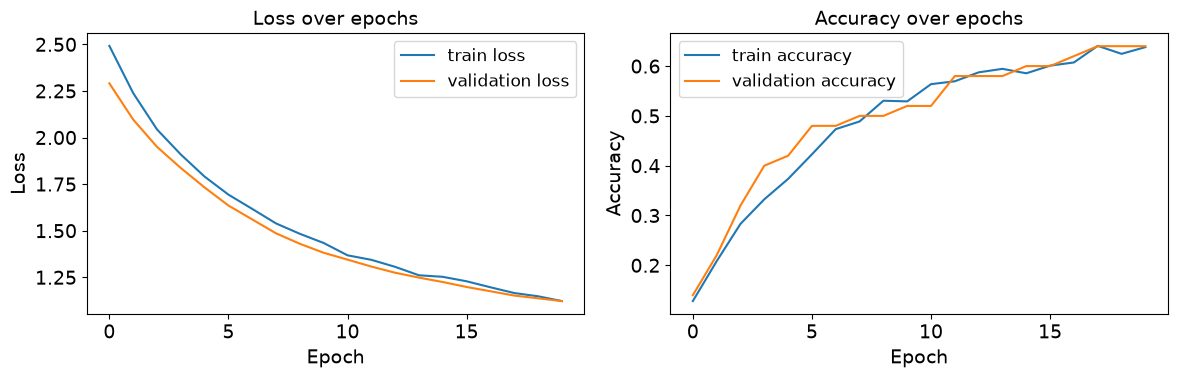

In [7]:
# Evaluate on the held-out test set.
test_loss, test_acc = tl_model.evaluate(test_flow, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')

# Plot the training curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['loss'], label='train loss')
axes[0].plot(history.history['val_loss'], label='validation loss')
axes[0].set_title('Loss over epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train accuracy')
axes[1].plot(history.history['val_accuracy'], label='validation accuracy')
axes[1].set_title('Accuracy over epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()


In [8]:
# Optional: unfreeze the last convolutional block and fine-tune the model.
# This is useful if the frozen-head model plateaus and we want a stronger final result.

base_model.trainable = True
for layer in base_model.layers[:-2]:
    layer.trainable = False

# Recompile with a smaller learning rate for fine-tuning.
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

fine_tune_history = tl_model.fit(
    train_flow,
    validation_data=valid_flow,
    epochs=5,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True,
        )
    ],
    verbose=1,
)

fine_tune_loss, fine_tune_acc = tl_model.evaluate(test_flow, verbose=0)
print(f'Fine-tuned test loss: {fine_tune_loss:.4f}')
print(f'Fine-tuned test accuracy: {fine_tune_acc:.4f}')


Epoch 1/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 9s 168ms/step - accuracy: 0.6445 - loss: 1.1191 - val_accuracy: 0.6600 - val_loss: 1.1212
Epoch 2/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 162ms/step - accuracy: 0.6509 - loss: 1.1176 - val_accuracy: 0.6600 - val_loss: 1.1187
Epoch 3/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 163ms/step - accuracy: 0.6329 - loss: 1.1107 - val_accuracy: 0.6600 - val_loss: 1.1173
Epoch 4/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 160ms/step - accuracy: 0.6381 - loss: 1.1232 - val_accuracy: 0.6600 - val_loss: 1.1162
Epoch 5/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 8s 165ms/step - accuracy: 0.6368 - loss: 1.1071 - val_accuracy: 0.6600 - val_loss: 1.1157
Fine-tuned test loss: 1.1221
Fine-tuned test accuracy: 0.7000
